# ¿Qué volcanes han tenido las erupciones más largas?

**Capítulo del curso:** Limpieza de datos (Open-Ended Project 2)

Dos tablas: las erupciones desde 1800 (con fechas `MM-AAAA`) y la lista de volcanes. Las limpio,
calculo la duración de cada erupción, las uno por `volcano_id` y respondo:

1. ¿Qué volcanes seguían en erupción en diciembre de 2024?
2. ¿Cuáles han tenido las erupciones más largas?
3. Extra: ¿qué pasa con los volcanes de Ecuador, como el **Tungurahua**, junto a Ambato?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

In [2]:
erupciones = pd.read_csv("datos/volcanic-eruptions.csv")
volcanes = pd.read_csv("datos/volcano-list.csv")
print(erupciones.shape, volcanes.shape)
erupciones.head(3)

(3724, 3) (1281, 14)


,volcano_id,start_date,end_date
0,211020,07-1913,04-1944
1,211020,02-1864,11-1868
2,211020,12-1854,05-1855


## Limpieza

Las fechas vienen como texto `MM-AAAA`. Las convierto a fecha y compruebo que no falte nada.

In [3]:
print("Valores nulos:", erupciones.isna().sum().to_dict())
print("Formato distinto de MM-AAAA:", (~erupciones["start_date"].str.match(r"^\d{2}-\d{4}$")).sum())

erupciones["inicio"] = pd.to_datetime(erupciones["start_date"], format="%m-%Y")
erupciones["fin"] = pd.to_datetime(erupciones["end_date"], format="%m-%Y")
erupciones["meses"] = (
    (erupciones["fin"].dt.year - erupciones["inicio"].dt.year) * 12
    + (erupciones["fin"].dt.month - erupciones["inicio"].dt.month)
)
erupciones["años"] = erupciones["meses"] / 12
print("Duraciones negativas:", (erupciones["meses"] < 0).sum())

Valores nulos: {'volcano_id': 0, 'start_date': 0, 'end_date': 0}
Formato distinto de MM-AAAA: 0
Duraciones negativas: 0


Antes de unir, me quedo solo con las columnas que necesito de cada tabla.

In [4]:
datos = erupciones[["volcano_id", "start_date", "end_date", "inicio", "años"]].merge(
    volcanes[["volcano_id", "volcano_name", "country", "elevation_m"]],
    on="volcano_id",
    how="left",
)
print("Erupciones sin volcán asociado:", datos["volcano_name"].isna().sum())
datos.head()

Erupciones sin volcán asociado: 0


,volcano_id,start_date,end_date,inicio,años,volcano_name,country,elevation_m
0,211020,07-1913,04-1944,1913-07-01,30.750000,Vesuvius,Italy,1281
1,211020,02-1864,11-1868,1864-02-01,4.750000,Vesuvius,Italy,1281
2,211020,12-1854,05-1855,1854-12-01,0.416667,Vesuvius,Italy,1281
3,211020,12-1855,12-1861,1855-12-01,6.000000,Vesuvius,Italy,1281
4,211020,07-1824,09-1834,1824-07-01,10.166667,Vesuvius,Italy,1281


## 1. Volcanes en erupción en diciembre de 2024

El dataset marca como `12-2024` el fin de las erupciones que seguían activas.

In [5]:
activas = datos[datos["end_date"] == "12-2024"].sort_values("inicio")
print(f"{len(activas)} erupciones seguían activas.")
activas[["volcano_name", "country", "start_date", "años"]].head(10).round(1).reset_index(drop=True)

41 erupciones seguían activas.


,volcano_name,country,start_date,años
0,Santa Maria,Guatemala,06-1922,102.5
1,Dukono,Indonesia,08-1933,91.3
2,Stromboli,Italy,02-1934,90.8
3,Erta Ale,Ethiopia,07-1967,57.4
4,Erebus,Antarctica,12-1972,52.0
5,Sheveluch,Russia,08-1999,25.3
6,Fuego,Guatemala,01-2002,22.9
7,Suwanosejima,Japan,10-2004,20.2
8,Popocatepetl,Mexico,01-2005,19.9
9,Ibu,Indonesia,04-2008,16.7


## 2. Las erupciones más largas

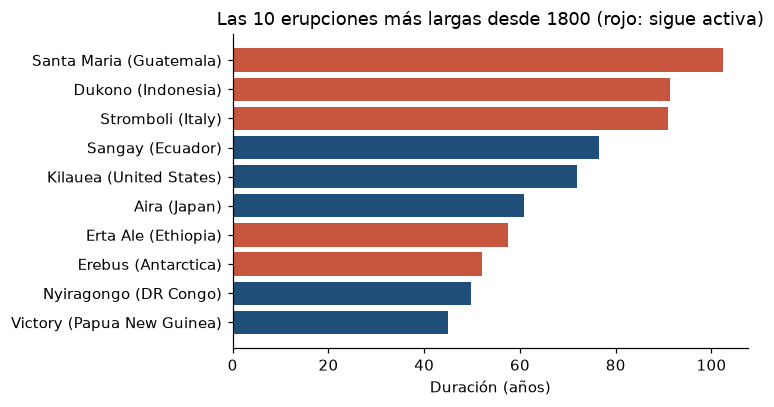

,volcano_name,country,start_date,end_date,años
0,Santa Maria,Guatemala,06-1922,12-2024,102.5
1,Dukono,Indonesia,08-1933,12-2024,91.3
2,Stromboli,Italy,02-1934,12-2024,90.8
3,Sangay,Ecuador,08-1934,03-2011,76.6
4,Kilauea,United States,02-1823,12-1894,71.8
5,Aira,Japan,10-1955,08-2016,60.8
6,Erta Ale,Ethiopia,07-1967,12-2024,57.4
7,Erebus,Antarctica,12-1972,12-2024,52.0
8,Nyiragongo,DR Congo,03-1927,01-1977,49.8
9,Victory,Papua New Guinea,01-1890,01-1935,45.0


In [6]:
largas = datos.sort_values("años", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(7, 3.8))
etiquetas = largas["volcano_name"] + " (" + largas["country"] + ")"
colores = ["#c8553d" if fin == "12-2024" else "#1f4e79" for fin in largas["end_date"]]
ax.barh(etiquetas[::-1], largas["años"][::-1], color=colores[::-1])
ax.set_xlabel("Duración (años)")
ax.set_title("Las 10 erupciones más largas desde 1800 (rojo: sigue activa)")
fig.tight_layout()
fig.savefig(FIG / "erupciones-mas-largas.png", bbox_inches="tight")
plt.show()

largas[["volcano_name", "country", "start_date", "end_date", "años"]].round(1).reset_index(drop=True)

## 3. Extra: volcanes de Ecuador

In [7]:
ecuador = datos[datos["country"] == "Ecuador"]
print("Erupciones registradas en Ecuador:", len(ecuador))
ecuador["volcano_name"].value_counts().head(6)

Erupciones registradas en Ecuador: 105


volcano_name
Fernandina          21
Cotopaxi            19
Reventador          12
Guagua Pichincha    11
Tungurahua           9
Sangay               9
Name: count, dtype: int64

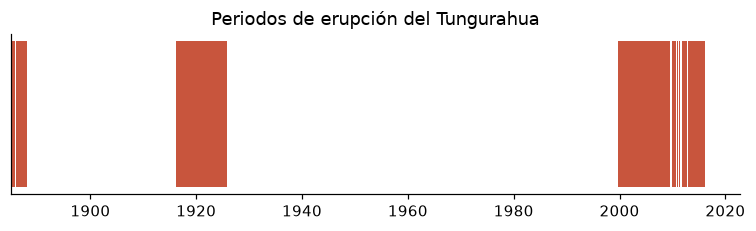

,start_date,end_date,años
0,01-1885,10-1885,0.8
1,01-1886,01-1888,2.0
2,03-1916,12-1925,9.8
3,10-1999,07-2009,9.8
4,01-2010,08-2010,0.6
5,11-2010,01-2011,0.2
6,04-2011,05-2011,0.1
7,11-2011,09-2012,0.8
8,12-2012,03-2016,3.2


In [8]:
tungurahua = ecuador[ecuador["volcano_name"] == "Tungurahua"].sort_values("inicio")

fig, ax = plt.subplots(figsize=(7, 2.2))
for _, fila in tungurahua.iterrows():
    ax.barh(0, fila["años"] * 365, left=fila["inicio"], height=0.5, color="#c8553d")
ax.set_yticks([])
ax.set_title("Periodos de erupción del Tungurahua")
fig.tight_layout()
fig.savefig(FIG / "tungurahua.png", bbox_inches="tight")
plt.show()

tungurahua[["start_date", "end_date", "años"]].round(1).reset_index(drop=True)

## Conclusiones

- Las fechas venían limpias (sin nulos ni formatos raros), pero había que convertirlas a fecha para poder restar.
- La erupción más larga es la del **Santa María** (Guatemala): empezó en 1922 y en 2024 seguía activa, más de 100 años.
  Le siguen **Dukono** (Indonesia) y **Stromboli** (Italia), también activos.
- 41 erupciones seguían activas en diciembre de 2024.
- En Ecuador, el **Sangay** tuvo una de las erupciones más largas del mundo (1934-2011, unos 77 años) y vuelve a estar
  activo desde 2019, igual que el **Reventador** desde 2008.
- El **Tungurahua** estuvo en erupción casi sin pausa entre 1999 y 2016: el periodo más largo duró casi 10 años.